# Insurance Claim Prediction (Part A - Machine Learning)

Objective: build and evaluate a classification model that predicts `insuranceclaim` from customer and policy data (`insurance2.csv`).

Run the notebook from the MiniProject folder so the CSV and the `plots/` output folder are found.

## Imports and setup

In [1]:
import os
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

HERE = os.getcwd()  # folder that holds insurance2.csv
DATA = os.path.join(HERE, "insurance2.csv")
PLOTS = os.path.join(HERE, "plots")
os.makedirs(PLOTS, exist_ok=True)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Task 1 - Dataset understanding

In [2]:
df = pd.read_csv(DATA)

print("First 5 records:\n", df.head(), "\n")
print("Last 5 records:\n", df.tail(), "\n")
print("Shape (rows, columns):", df.shape)
print("Column names:", list(df.columns))
print("\nData types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDescriptive statistics:\n", df.describe().T)

# Categorical columns are stored as integer codes. The mapping of region codes
# to region names is not in the file, so region is treated as nominal (one-hot).
NUMERICAL = ["age", "bmi", "children", "charges"]
CATEGORICAL = ["sex", "smoker", "region"]
TARGET = "insuranceclaim"

print("\nTarget distribution (counts):\n", df[TARGET].value_counts())
print("\nTarget distribution (proportions):\n", df[TARGET].value_counts(normalize=True).round(4))

First 5 records:
    age  sex     bmi  children  smoker  region      charges  insuranceclaim
0   19    0  27.900         0       1       3  16884.92400               1
1   18    1  33.770         1       0       2   1725.55230               1
2   28    1  33.000         3       0       2   4449.46200               0
3   33    1  22.705         0       0       1  21984.47061               0
4   32    1  28.880         0       0       1   3866.85520               1 

Last 5 records:
       age  sex    bmi  children  smoker  region     charges  insuranceclaim
1333   50    1  30.97         3       0       1  10600.5483               0
1334   18    0  31.92         0       0       0   2205.9808               1
1335   18    0  36.85         0       0       2   1629.8335               1
1336   21    0  25.80         0       0       3   2007.9450               0
1337   61    0  29.07         0       1       1  29141.3603               1 

Shape (rows, columns): (1338, 8)
Column names: ['age', 

## Task 2 - Exploratory data analysis (univariate)

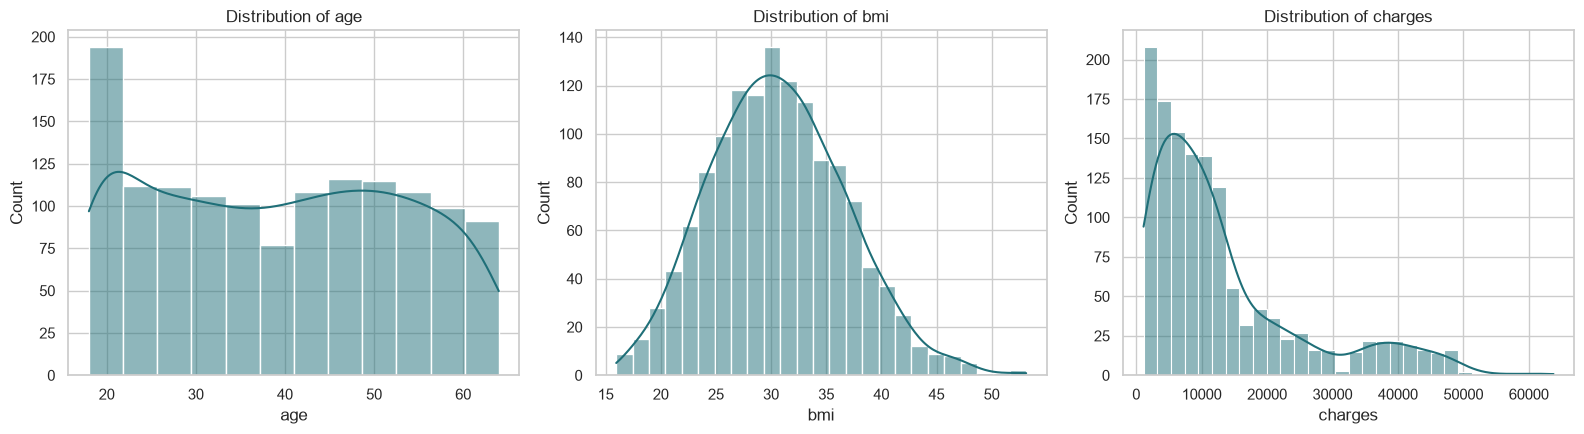

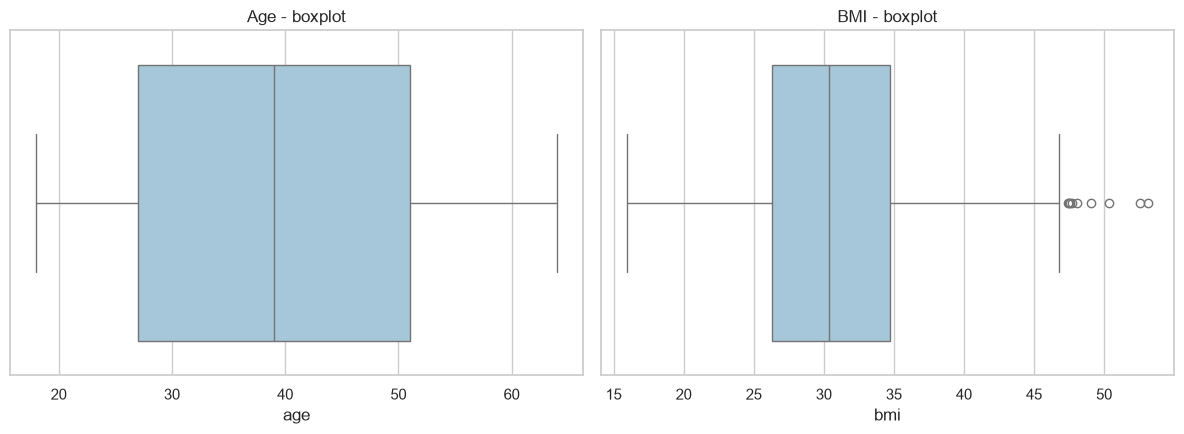

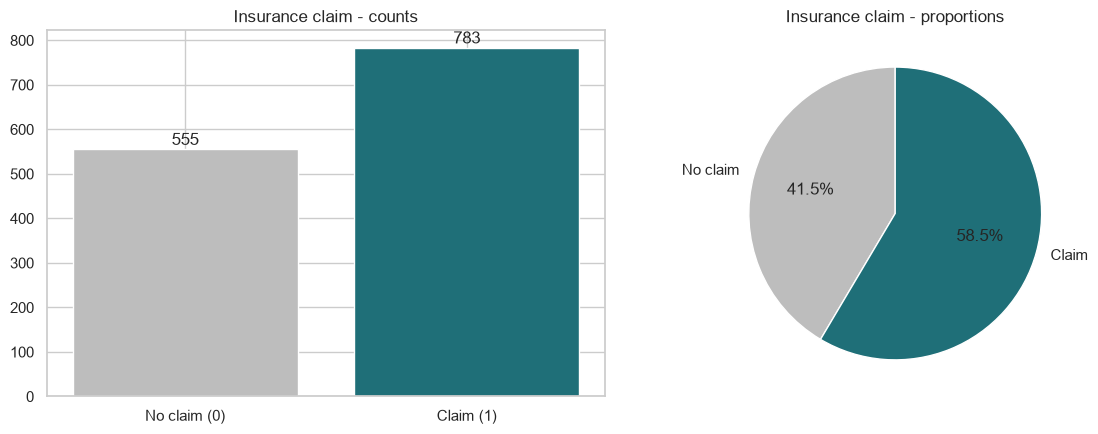

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["age", "bmi", "charges"]):
    sns.histplot(df[col], kde=True, ax=ax, color="#1f6f78")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS, "01_univariate_age_bmi_charges.png"), dpi=120)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x=df["age"], ax=axes[0], color="#9ecae1")
axes[0].set_title("Age - boxplot")
sns.boxplot(x=df["bmi"], ax=axes[1], color="#9ecae1")
axes[1].set_title("BMI - boxplot")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS, "02_boxplots_age_bmi.png"), dpi=120)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts = df[TARGET].value_counts().sort_index()
axes[0].bar(["No claim (0)", "Claim (1)"], counts.values, color=["#bdbdbd", "#1f6f78"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 10, str(v), ha="center")
axes[0].set_title("Insurance claim - counts")
axes[1].pie(counts.values, labels=["No claim", "Claim"], autopct="%1.1f%%",
            colors=["#bdbdbd", "#1f6f78"], startangle=90)
axes[1].set_title("Insurance claim - proportions")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS, "03_univariate_insuranceclaim.png"), dpi=120)

## Task 2 - Bivariate / multivariate context (supports the modelling choices)

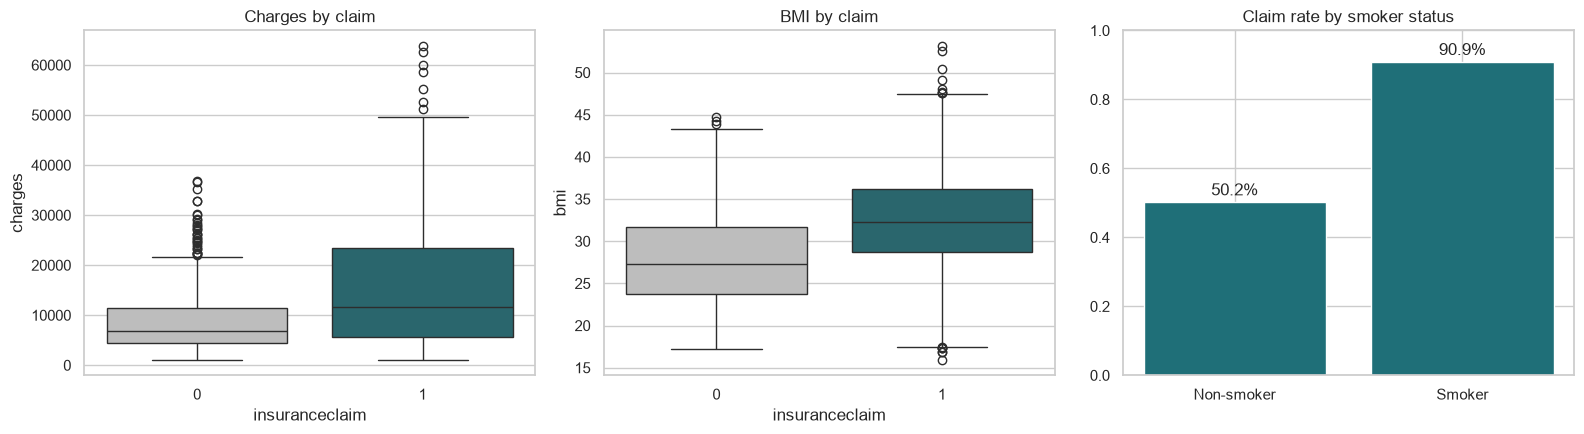

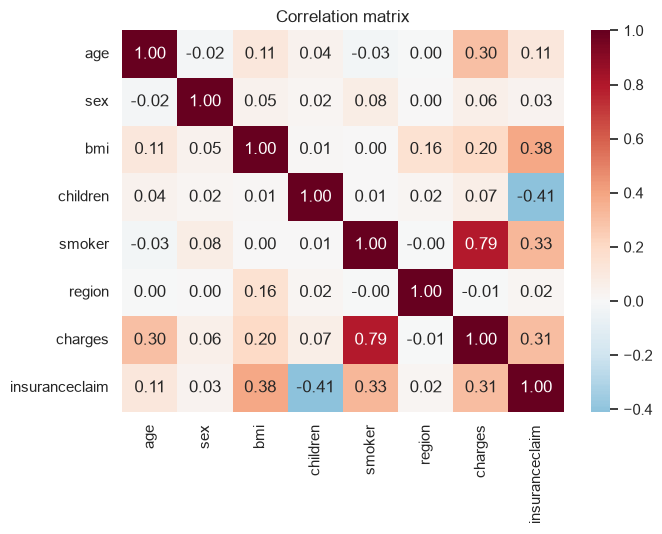

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(x=TARGET, y="charges", hue=TARGET, data=df, ax=axes[0], palette=["#bdbdbd", "#1f6f78"], legend=False)
axes[0].set_title("Charges by claim")
sns.boxplot(x=TARGET, y="bmi", hue=TARGET, data=df, ax=axes[1], palette=["#bdbdbd", "#1f6f78"], legend=False)
axes[1].set_title("BMI by claim")
claim_rate_smoker = df.groupby("smoker")[TARGET].mean()
axes[2].bar(["Non-smoker", "Smoker"], claim_rate_smoker.values, color="#1f6f78")
axes[2].set_ylim(0, 1)
axes[2].set_title("Claim rate by smoker status")
for i, v in enumerate(claim_rate_smoker.values):
    axes[2].text(i, v + 0.02, f"{v:.1%}", ha="center")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS, "04_bivariate_vs_claim.png"), dpi=120)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS, "05_correlation_heatmap.png"), dpi=120)

## Task 3 - Preprocessing

In [5]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Stratified split keeps the claim ratio the same in train and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("\nTrain shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train claim ratio:", round(y_train.mean(), 4), " Test claim ratio:", round(y_test.mean(), 4))

# Scaling and one-hot encoding are placed inside a Pipeline. When the pipeline is
# fitted, the scaler and encoder learn their statistics from X_train only.
# Test data is only transformed with those training statistics (no leakage).
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERICAL),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), ["region"]),
    ],
    remainder="passthrough",  # sex and smoker are already binary 0/1
)


Train shape: (1070, 7)  Test shape: (268, 7)
Train claim ratio: 0.585  Test claim ratio: 0.5858


## Task 4 - Build and train models

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
}

results = []
fitted = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", estimator)])
    pipe.fit(X_train, y_train)                       # 1. train
    y_pred = pipe.predict(X_test)                    # 2. predictions
    y_proba = pipe.predict_proba(X_test)[:, 1]       # 3. probabilities of class 1
    fitted[name] = (pipe, y_pred, y_proba)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

    # Cross-validation on the training set only (pipeline refits each fold)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"\n{name} - 5-fold CV ROC-AUC on training set: "
          f"{cv_auc.mean():.4f} +/- {cv_auc.std():.4f}")

    print(f"\n{name} - classification report (test set):")
    print(classification_report(y_test, y_pred, target_names=["No claim", "Claim"]))

results_df = pd.DataFrame(results).set_index("Model").round(4)
print("\nModel comparison (test set):\n", results_df)


Logistic Regression - 5-fold CV ROC-AUC on training set: 0.9257 +/- 0.0358

Logistic Regression - classification report (test set):
              precision    recall  f1-score   support

    No claim       0.83      0.83      0.83       111
       Claim       0.88      0.88      0.88       157

    accuracy                           0.86       268
   macro avg       0.85      0.85      0.85       268
weighted avg       0.86      0.86      0.86       268




Random Forest - 5-fold CV ROC-AUC on training set: 0.9921 +/- 0.0041

Random Forest - classification report (test set):
              precision    recall  f1-score   support

    No claim       0.96      0.95      0.95       111
       Claim       0.96      0.97      0.97       157

    accuracy                           0.96       268
   macro avg       0.96      0.96      0.96       268
weighted avg       0.96      0.96      0.96       268


Model comparison (test set):
                      Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                            
Logistic Regression    0.8582     0.8790  0.8790  0.8790   0.9031
Random Forest          0.9627     0.9623  0.9745  0.9684   0.9917


## Task 4 - Evaluation plots


Logistic Regression coefficients (standardised numeric features):
 children   -1.7314
region_1   -0.3493
region_2   -0.3324
region_3   -0.1434
sex         0.1852
age         0.2694
charges     0.3207
bmi         1.5413
smoker      3.3689
dtype: float64



Plots saved to: C:\Users\284448\Documents\100NextGenAICohort5\MiniProject\plots


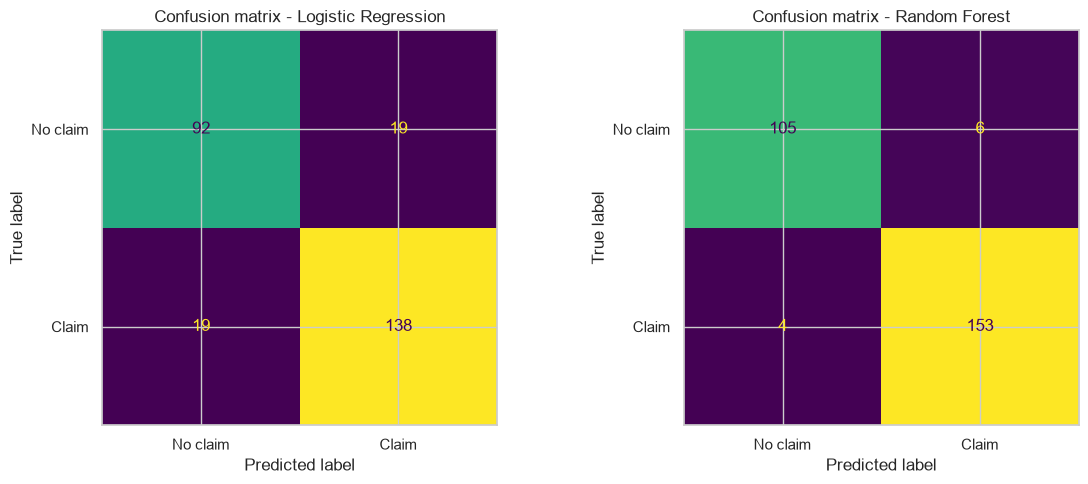

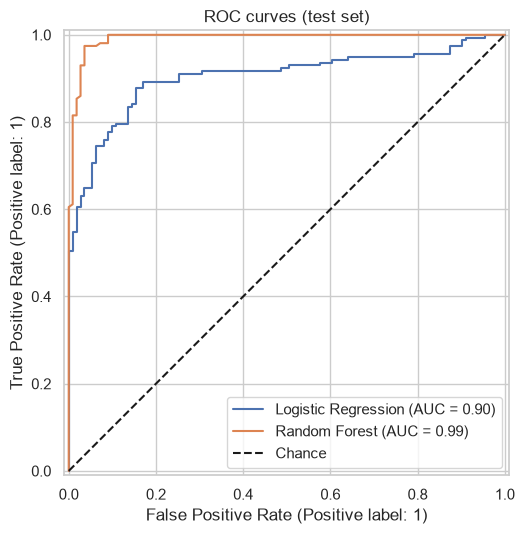

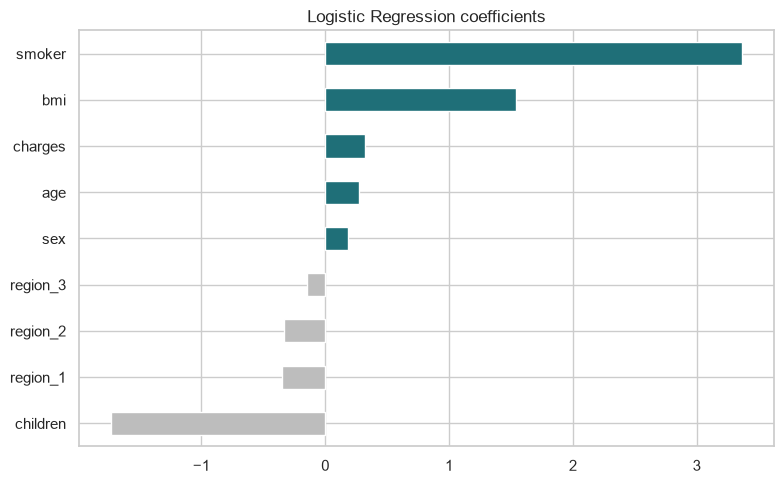

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, (pipe, y_pred, _)) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["No claim", "Claim"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"Confusion matrix - {name}")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS, "06_confusion_matrices.png"), dpi=120)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, (pipe, _, y_proba) in fitted.items():
    RocCurveDisplay.from_predictions(y_test, y_proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("ROC curves (test set)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOTS, "07_roc_curves.png"), dpi=120)

# Logistic regression coefficients (on scaled features) show direction of effect
lr_pipe = fitted["Logistic Regression"][0]
feature_names = (NUMERICAL
                 + list(lr_pipe.named_steps["preprocess"]
                        .named_transformers_["cat"].get_feature_names_out(["region"]))
                 + ["sex", "smoker"])  # passthrough columns come last
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=feature_names).sort_values()
print("\nLogistic Regression coefficients (standardised numeric features):\n", coefs.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
coefs.plot(kind="barh", ax=ax, color=np.where(coefs.values >= 0, "#1f6f78", "#bdbdbd"))
ax.set_title("Logistic Regression coefficients")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS, "08_logreg_coefficients.png"), dpi=120)

print("\nPlots saved to:", PLOTS)